# Task 2: Bike Sharing Demand Prediction System
**Problem:** Predict the number of bikes rented per hour (`cnt`) from weather, season and calendar features. It is a regression problem, like the Car Price Prediction System in Task 1.

**Dataset:** Capital Bikeshare (Washington D.C., 2011-2012), the **full hourly dataset**, 17,379 rows ([UCI Bike Sharing Dataset](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset)).

**Evaluation:** 5 algorithms, each evaluated on the **full dataset with 10-Fold Cross-Validation**.

| # | Algorithm | Used in Task 1? |
|---|-----------|-----------------|
| 1 | Support Vector Regression (RBF) | No |
| 2 | Neural Network (MLPRegressor) | No |
| 3 | Poisson Regression (GLM for count data) | No |
| 4 | ElasticNet (L1+L2 regularised linear model) | No |
| 5 | AdaBoost Regressor | No |

Task 1 used Linear Regression, KNN, Decision Tree, Random Forest and Gradient Boosting, so none of those appear here.

**Run on Google Colab:** Runtime > Run all. When asked, upload `hour.csv` (it is also auto-downloaded from UCI if available).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib, time, warnings, os
from sklearn.model_selection import KFold, cross_validate
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import PoissonRegressor, ElasticNet
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 1. Download / load the full dataset

In [2]:
def load_data():
    if os.path.exists('hour.csv'):
        return pd.read_csv('hour.csv')
    try:  # Colab: download the full dataset from UCI
        import urllib.request, zipfile, io
        url = 'https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip'
        z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=30).read()))
        return pd.read_csv(z.open('hour.csv'))
    except Exception as e:
        print('Auto-download failed:', e, '\nPlease upload hour.csv')
        from google.colab import files; files.upload()
        return pd.read_csv('hour.csv')

df = load_data()
print('Shape:', df.shape, '| Missing:', df.isna().sum().sum(), '| Duplicates:', df.duplicated().sum())
df.head()

Shape: (17379, 17) | Missing: 0 | Duplicates: 0


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.000000,5017.029500,1.00,4345.5000,8690.0000,13034.5000,17379.0000
season,17379.0,2.501640,1.106918,1.00,2.0000,3.0000,3.0000,4.0000
yr,17379.0,0.502561,0.500008,0.00,0.0000,1.0000,1.0000,1.0000
mnth,17379.0,6.537775,3.438776,1.00,4.0000,7.0000,10.0000,12.0000
hr,17379.0,11.546752,6.914405,0.00,6.0000,12.0000,18.0000,23.0000
holiday,17379.0,0.028770,0.167165,0.00,0.0000,0.0000,0.0000,1.0000
weekday,17379.0,3.003683,2.005771,0.00,1.0000,3.0000,5.0000,6.0000
workingday,17379.0,0.682721,0.465431,0.00,0.0000,1.0000,1.0000,1.0000
weathersit,17379.0,1.425283,0.639357,1.00,1.0000,1.0000,2.0000,4.0000
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000


## 2. Exploratory Data Analysis

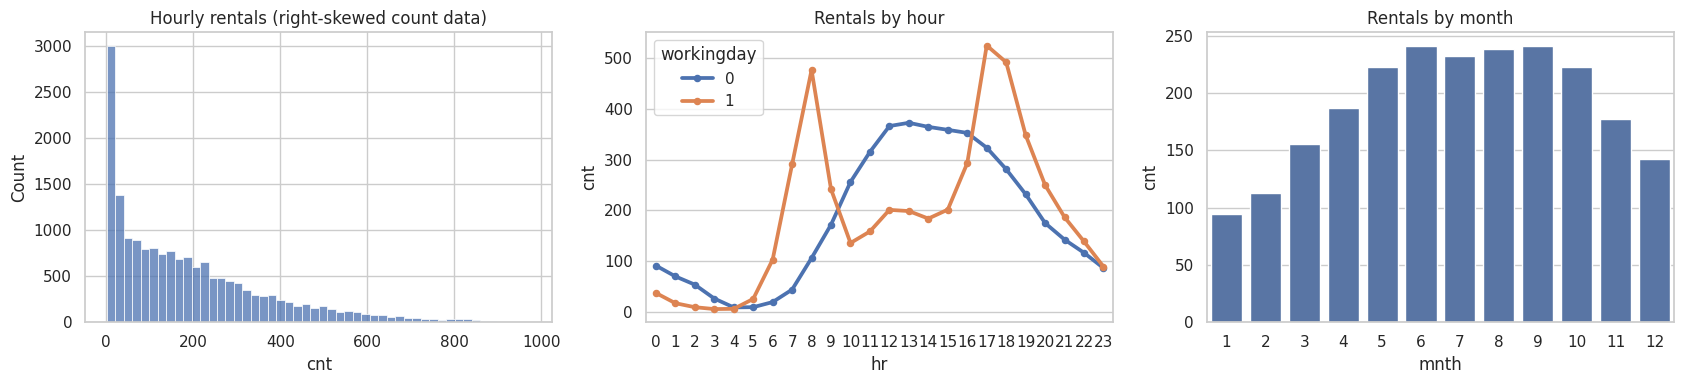

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(df['cnt'], bins=50, ax=ax[0]); ax[0].set_title('Hourly rentals (right-skewed count data)')
sns.pointplot(data=df, x='hr', y='cnt', hue='workingday', ax=ax[1], errorbar=None, markers='.'); ax[1].set_title('Rentals by hour')
sns.barplot(data=df, x='mnth', y='cnt', ax=ax[2], errorbar=None); ax[2].set_title('Rentals by month')
plt.tight_layout(); plt.show()

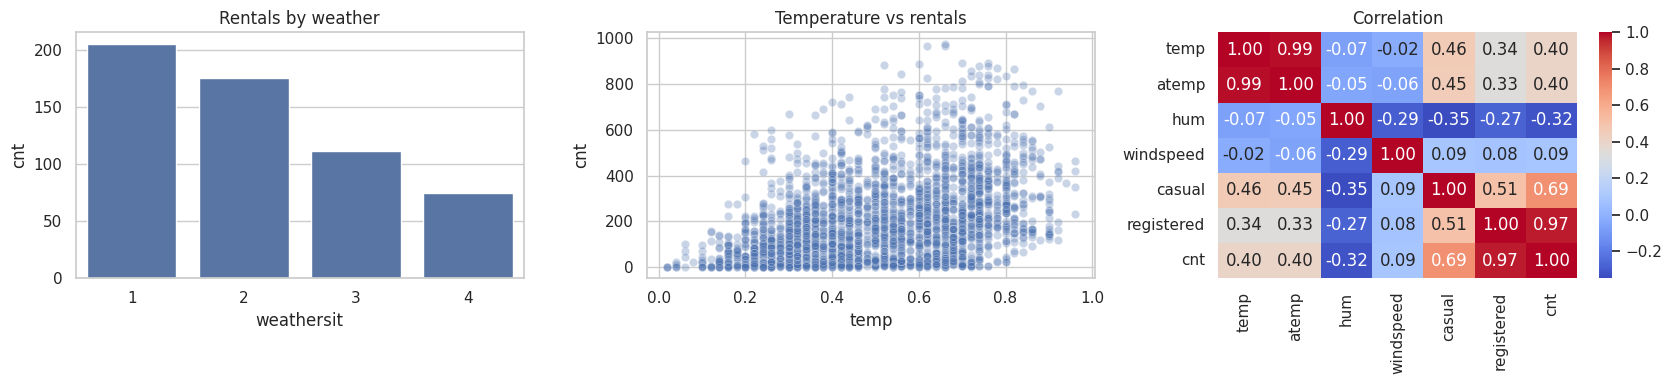

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.barplot(data=df, x='weathersit', y='cnt', ax=ax[0], errorbar=None); ax[0].set_title('Rentals by weather')
sns.scatterplot(data=df.sample(3000, random_state=1), x='temp', y='cnt', alpha=.3, ax=ax[1]); ax[1].set_title('Temperature vs rentals')
sns.heatmap(df[['temp','atemp','hum','windspeed','casual','registered','cnt']].corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax[2]); ax[2].set_title('Correlation')
plt.tight_layout(); plt.show()

**Findings:** rush-hour peaks (8am, 5-6pm) on working days; demand rises with temperature and falls in bad weather; 2012 > 2011. `temp`/`atemp` are almost identical (drop `atemp`), and `casual + registered = cnt` (using them would be data leakage, so they are dropped).

## 3. Preprocessing
Dropped: `instant`, `dteday`, `casual`, `registered`, `atemp`. Categorical-style columns are one-hot encoded, `temp/hum/windspeed` are standardised. Everything is wrapped in a **Pipeline**, so inside every CV fold the encoder/scaler are fitted only on that fold's training data (no leakage). For models that benefit from it, the target is modelled as `log1p(cnt)`.

In [6]:
cat_cols = ['season','mnth','hr','weekday','weathersit']
bin_cols = ['yr','holiday','workingday']
num_cols = ['temp','hum','windspeed']
features = cat_cols + bin_cols + num_cols
X, y = df[features], df['cnt']

def pipe(estimator, log_target=True):
    pre = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
                             ('bin', 'passthrough', bin_cols),
                             ('num', StandardScaler(), num_cols)])
    model = TransformedTargetRegressor(regressor=estimator, func=np.log1p, inverse_func=np.expm1) if log_target else estimator
    return Pipeline([('prep', pre), ('model', model)])

models = {
 'SVR (RBF)':            pipe(SVR(kernel='rbf', C=10, epsilon=0.1)),
 'Neural Network (MLP)': pipe(MLPRegressor(hidden_layer_sizes=(128,64), alpha=1e-3, max_iter=500, early_stopping=True, random_state=RANDOM_STATE)),
 'Poisson Regression':   pipe(PoissonRegressor(alpha=1e-4, max_iter=1000), log_target=False),
 'ElasticNet':           pipe(ElasticNet(alpha=1e-3, l1_ratio=0.5, max_iter=5000)),
 'AdaBoost':             pipe(AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=8), n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE)),
}

## 4. 10-Fold Cross-Validation on the FULL dataset

In [7]:
kf = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
scoring = {'rmse':'neg_root_mean_squared_error', 'mae':'neg_mean_absolute_error', 'r2':'r2'}
cv_results, rows = {}, []
for name, m in models.items():
    t = time.time()
    r = cross_validate(m, X, y, cv=kf, scoring=scoring, n_jobs=-1)
    cv_results[name] = r
    rows.append({'Model':name, 'RMSE (mean)':-r['test_rmse'].mean(), 'RMSE (std)':r['test_rmse'].std(),
                 'MAE (mean)':-r['test_mae'].mean(), 'R2 (mean)':r['test_r2'].mean(), 'R2 (std)':r['test_r2'].std(),
                 'Time (s)':time.time()-t})
    print(f'{name:22s} done in {time.time()-t:.0f}s')
results = pd.DataFrame(rows).set_index('Model').sort_values('RMSE (mean)').round(3)
results

SVR (RBF)              done in 1055s


Neural Network (MLP)   done in 32s


Poisson Regression     done in 1s


ElasticNet             done in 1s


AdaBoost               done in 58s


,RMSE (mean),RMSE (std),MAE (mean),R2 (mean),R2 (std),Time (s)
Model,,,,,,
SVR (RBF),44.413,2.570,26.491,0.940,0.007,1055.191
Neural Network (MLP),45.176,1.937,27.584,0.938,0.006,32.355
Poisson Regression,90.267,2.523,60.410,0.752,0.015,1.432
ElasticNet,98.681,2.441,63.386,0.704,0.011,0.567
AdaBoost,143.853,4.830,85.676,0.371,0.017,57.602


## 5. Comparison

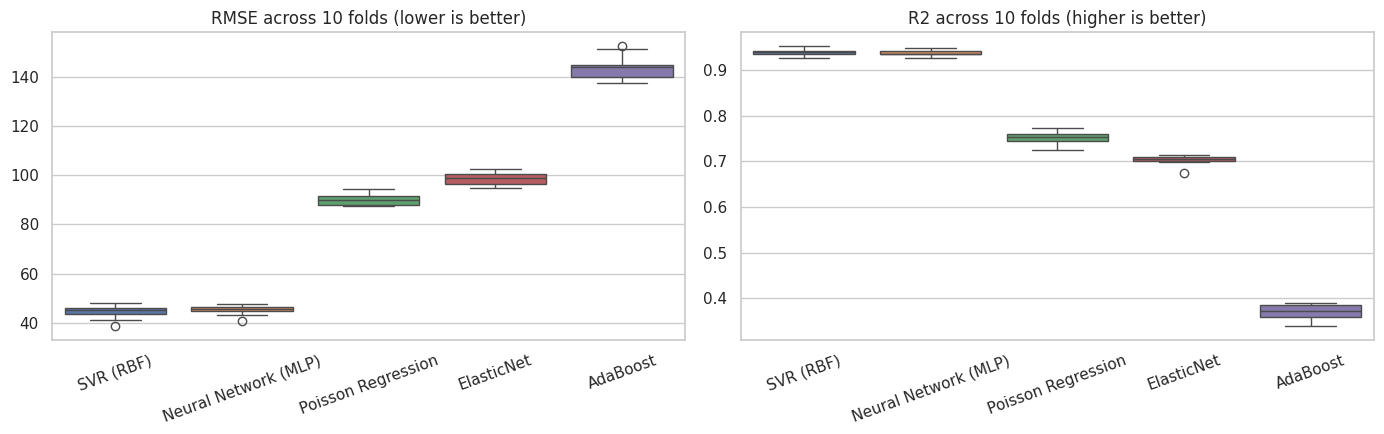

Best algorithm: SVR (RBF)


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
order = results.index
rmse_df = pd.DataFrame({n:-cv_results[n]['test_rmse'] for n in order}); r2_df = pd.DataFrame({n:cv_results[n]['test_r2'] for n in order})
sns.boxplot(data=rmse_df, ax=ax[0]); ax[0].set_title('RMSE across 10 folds (lower is better)'); ax[0].tick_params(axis='x', rotation=20)
sns.boxplot(data=r2_df, ax=ax[1]); ax[1].set_title('R2 across 10 folds (higher is better)'); ax[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()
best_name = results.index[0]; print('Best algorithm:', best_name)

## 6. Train the best model on the full dataset and save it for deployment

In [9]:
best_model = models[best_name].fit(X, y)
joblib.dump({'model':best_model, 'features':features, 'name':best_name, 'metrics':results.loc[best_name].to_dict()}, 'model.joblib')
sample = pd.DataFrame([{'season':3,'mnth':7,'hr':17,'weekday':3,'weathersit':1,'yr':1,'holiday':0,'workingday':1,'temp':0.7,'hum':0.5,'windspeed':0.2}])
print('Sanity check, clear July weekday 5pm ->', int(best_model.predict(sample)[0]), 'bikes')
try:
    from google.colab import files; files.download('model.joblib')   # on Colab: download model for the Streamlit app
except Exception: pass

Sanity check, clear July weekday 5pm -> 887 bikes


## 7. Conclusion
- Five algorithms **not used in Task 1** were compared with 10-fold CV on all 17,379 records.
- The table in section 4 gives mean RMSE / MAE / R2 (with fold-to-fold std). The best model is saved as `model.joblib` and served by the Streamlit app (`app.py`).
- Poisson Regression is included because rentals are non-negative counts; ElasticNet shows what a regularised linear model can do; SVR and the MLP capture non-linear hour x weather interactions; AdaBoost is a boosted-stump/tree ensemble.
- **Deployment:** see `README.md` (GitHub + Streamlit Community Cloud).

*Dataset: Fanaee-T, H. & Gama, J. (2013), Event labeling combining ensemble detectors and background knowledge, Progress in Artificial Intelligence.*